# Assignment 3: Sampling Distributions and Estimation
Authored by Kristian M. P. Dashnaw (344849) & Katrine B. Aamand (344848) <br>
Based on assignment 3 description (https://rbrooksdk.github.io/STA1_26/assignments/assignment_03_sampling_and_estimation/)

## Table of Contents

1. **Part 1 — Sampling distributions and the CLT**
    - 1.1 Simulated Sample Means and Summary Table
    - 1.2 Sampling Distributions with Normal Overlays
    - 1.3 Tail Probability $P(\bar X>75)$: Simulation vs. CLT
    - 1.4 Smallest $n$ with $\operatorname{SE}(\bar X)\le6$ Minutes
    - 1.5 Running Mean and the Law of Large Numbers
    - CLT Scope Statement
2. **Part 2 — Estimating mean sensor error**
    - 2.1 Summary Statistics and Standard Error
    - 2.2 Histogram, QQ-Plot, and $t$-Interval Suitability
    - 2.3 95% $t$ Interval: Components and SciPy Verification
    - 2.4 90%, 95%, and 99% $t$ Intervals and Widths
    - 2.5 Sample-Size Planning for a 0.10 °C Margin of Error
    - 2.6 Percentile Bootstrap Interval
3. **Part 3 — Estimating a false-rejection proportion**
    - 3.1 Sample Size, False Rejections, and $\hat p$
    - 3.2 95% Wilson Interval
    - 3.3 95% Wald Interval and Comparison with Wilson
    - 3.4 90%, 95%, and 99% Wilson Intervals and Widths
    - 3.5 Sample-Size Planning for a 0.02 Margin of Error
4. **Part 4 — AI-Use and Conclusion**
    - AI-Use Statement
    - Overall Conclusion

## Working Notes

**How to present the work (from the assignment description):**

> Use executed code for every simulation, estimate, interval, table, and plot. Use Markdown for model statements, formulas, assumptions, coverage interpretations, and conclusions. Show requested interval components before verifying with a library function.

In [43]:
#Imports:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from scipy.stats import probplot
from scipy import stats

# Load the data files:
print("\nSensor_Calibration.csv, first 5 rows:")
sensorCalibrationData_unmodified = pd.read_csv('data/assignment03_sensor_calibration.csv', delimiter = ',')
display(sensorCalibrationData_unmodified.head(5))

print("\n\nAccess_Control.csv, first 5 rows:")
accessControlData_unmodified = pd.read_csv('data/assignment03_access_control.csv', delimiter = ',')
display(accessControlData_unmodified.head(5))


Sensor_Calibration.csv, first 5 rows:


,sensor_id,calibration_error_c
0,1,0.334
1,2,0.383
2,3,1.644
3,4,0.627
4,5,0.615




Access_Control.csv, first 5 rows:


,attempt_id,false_reject
0,1,0
1,2,0
2,3,0
3,4,1
4,5,0


<br><br><br>

---

<br><br>

## Part 1: Sampling distributions and the CLT

Restoration time in a service system is modelled as exponential with population mean and standard deviation $\mu=\sigma=60$ minutes. Use this known population model and NumPy's random generator with seed 2026 and at least 20,000 repetitions per sample size.

<br><br>

<br>

### 1.1 Simulate samples for $n=1,5,20,80$ and store their means. Create a table with $n$, theoretical mean, simulated mean of means, theoretical standard error $\sigma/\sqrt n$, and empirical standard deviation of the simulated means.

In [2]:
# TODO: Katrine

<br><br>
### 1.2 Create one figure showing the four sampling distributions with density histograms and overlay $N(\mu,\sigma^2/n)$. Explain how centre, spread, and shape change and why the normal curve is an approximation for this non-normal population.

In [3]:
# TODO: Katrine

<br><br>
### 1.3 For $n=20$ and $n=80$, estimate $P(\bar X>75)$ by simulation and calculate the CLT approximation. Compare the values.

In [4]:
# TODO: Katrine

<br><br>
### 1.4 Find the smallest integer $n$ for which $\operatorname{SE}(\bar X)\le6$ minutes and verify it by simulation.


In [5]:
# TODO: Katrine

<br><br>

### 1.5 Generate one sequence of 5,000 observations and plot its running mean. Explain the law of large numbers and how this plot differs from a sampling distribution.

In [6]:
# TODO: Katrine

### CLT Scope Statement

> State explicitly that the CLT concerns sample means. It neither makes individual restoration times normal nor repairs dependence, drift, or unrepresentative sampling.

Det her felt skal slettes inden aflevering, og ovenstående statement skal skrives ind i findings og/eller konklusion! Den er med her, fordi den er anført i selve assignment teksten i slutningen af part 1, men ikke tilhørende et specifikt underspørgsmål

<br><br><br>

---

<br>

## Part 2: Estimating mean sensor error

The file [assignment03_sensor_calibration.csv](./data/assignment03_sensor_calibration.csv) contains calibration errors from 64 independently selected temperature sensors. Error is `sensor reading − reference temperature`. Let $\mu$ be the population mean calibration error.

<br><br>
### 2.1 Report $n$, $\bar x$, $s$, and the estimated standard error. Explain standard deviation versus standard error.

#### Defining the parameters from above:

##### $n$ is the sample size (i.e. number of observations in the sample)

<br>

##### $\bar x$ is the sample mean (i.e. observed estimate, as opposed to $\bar X$, which is a Random statistic (Estimator)). This is defined by definition 5.5 in the course book:

For observed values $x_{1},\ldots,x_{n}$, its realised value is

$$
\bar{x}=\frac{1}{n}\sum_{i=1}^{n}x_{i}.
$$

<br>

##### $s$ is the observed sample standard deviation (i.e. observed estimate, as opposed to $S$, which is a Random statistic (Estimator)). This is defined by definition 5.7 in the course book:

$$
s^{2}=\frac{1}{n-1}\sum_{i=1}^{n}\left(x_{i}-\bar{x}\right)^{2}.
$$

So the sample standard deviation is $S=\sqrt{S^{2}}$, with observed value $s$.

<br>

##### The standard error is given by the definition 5.6 in the course book as:

The **standard error** of a statistic is the standard deviation of its sampling distribution. For the sample mean,

$$\mathrm{SE}(\bar X) = \frac{\sigma}{\sqrt{n}}$$

If $\sigma$ is unknown, it is commonly estimated by

$$
\widehat{\mathrm{SE}}(\bar{X})=\frac{S}{\sqrt{n}}
$$



In [4]:
# Kristian
x = sensorCalibrationData_unmodified["calibration_error_c"].to_numpy()
n = x.size
xbar = x.mean()
s = x.std(ddof=1)
se = s / np.sqrt(n)

print(f"n = {n}")
print(f"estimate xbar  = {xbar:.3f}")
print(f"sample SD s    = {s:.3f}")
print(f"SE(Xbar)       = {se:.3f}")

n = 64
estimate xbar  = 0.188
sample SD s    = 0.626
SE(Xbar)       = 0.078


#### Explaining Standard Deviation versus Standard Error
**The observed standard deviation** $s$ is a measure for the **variation among the individual observations**. It does not necessarily become smaller just because more data is collected.

**The Standard Error** $\frac{S}{\sqrt{n}}$ is a measure for the **variation among means from repeated samples of size $n$**. It becomes smaller the more data is collected (at the rate of $\frac{1}{\sqrt{n}}$)

For this sample, this means that we use $s$ to measure how much the calibration errors vary from sensor to sensor, while the standard error describes how much the sample mean ($\bar x$) is estimated to vary if these observations were done again with 64 new sensors. Therefor, the standard error measures how precisely $\bar x$ estimates the population mean calibration error $\mu$.


<br><br>
### 2.2 Create a histogram and normal QQ-plot. Discuss whether a one-sample $t$ interval appears reasonable and why plots cannot establish independence.

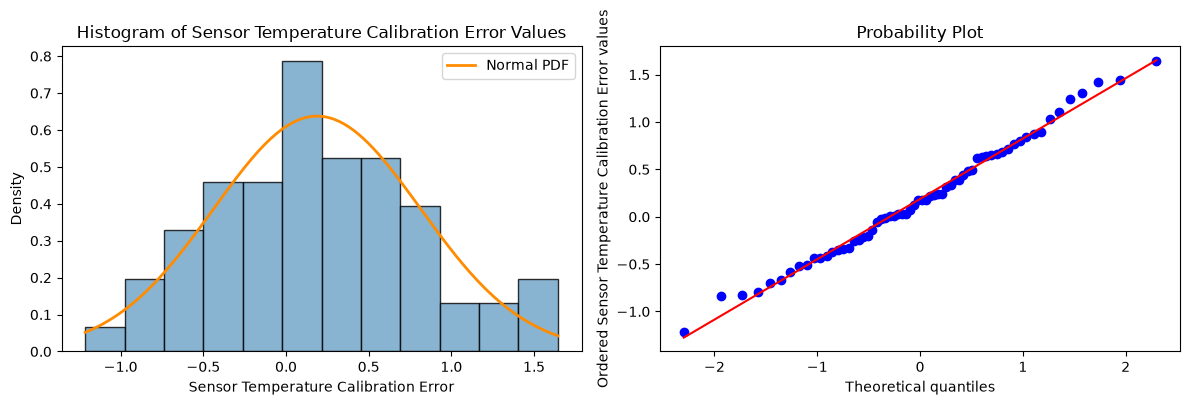

In [50]:
# Kristian

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
xs = np.linspace(x.min(), x.max(), 200)
axes[0].hist(x, bins=12, density=True, edgecolor="black", color="#6CA2C6", alpha=0.8)
axes[0].plot(xs, stats.norm(loc=xbar, scale=s).pdf(xs), color="#FF8C00", lw=2, label="Normal PDF")
axes[0].set_title("Histogram of Sensor Temperature Calibration Error Values")
axes[0].set_xlabel("Sensor Temperature Calibration Error")
axes[0].set_ylabel("Density")
axes[0].legend()
probplot(x, plot=axes[1])
axes[1].set_xlabel("Theoretical quantiles")
axes[1].set_ylabel("Ordered Sensor Temperature Calibration Error values")
plt.tight_layout()
plt.show()

#### Discussion: Is a one-sample t interval reasonable?
TODO

#### Discussion: Why plots cannot establish independence:
TODO

<br><br>
### 2.3 Construct a 95% $t$ interval by calculating the degrees of freedom, critical value, standard error, and margin of error. Verify it with SciPy and interpret both the interval and the 95% confidence level correctly.

In [9]:
# TODO: Kristian

<br><br>
### 2.4 Create a table of 90%, 95%, and 99% $t$ intervals and widths. Explain the confidence–precision trade-off.

In [10]:
# TODO: Kristian

<br><br>
### 2.5 Using $s$ as a planning value and the normal critical value, find the smallest approximate sample size for a 95% margin of error no larger than $0.10\ ^\circ\mathrm C$.

In [11]:
# TODO: Kristian

### 2.6 With seed 2026 and at least 10,000 resamples, construct a percentile bootstrap interval. Compare it with the $t$ interval and state what the comparison cannot validate.

In [12]:
# TODO: Kristian

<br><br><br>

---

<br>

## Part 3: Estimating a false-rejection proportion

The file [assignment03_access_control.csv](./data/assignment03_access_control.csv) contains 240 independently staged legitimate login attempts. `false_reject` equals 1 when a legitimate attempt was rejected and 0 otherwise. Let $p$ be the population false-rejection probability under the test conditions.

<br><br>
### 3.1 Report $n$, the number of false rejections $x$, and $\hat p$. Explain why $\hat p$ is also the sample mean of a binary variable.

In [13]:
# TODO: Katrine

<br><br>
### 3.2 Construct and interpret a 95% Wilson interval for $p$ with statsmodels. State the population and parameter clearly.

In [14]:
# TODO: Katrine

<br><br><br>
### 3.3 Calculate the 95% Wald interval from its formula. Compare it with Wilson and explain why Wilson is the preferred default.

In [15]:
# TODO: Katrine

<br><br>
### 3.4 Create a table of 90%, 95%, and 99% Wilson intervals and widths.

In [16]:
# TODO: Kristian

<br><br>
### 3.5 Estimate the sample size for a 95% margin of error no larger than 0.02 using first $p=0.5$ and then the observed $\hat p$. Round up and explain the difference.

In [17]:
# TODO: Kristian

<br><br><br>

---

<br>

## Part 4: AI-Use and Conclusion
### AI-use
> State which AI tools you used, what they contributed, what you changed or rejected, and how you verified the work. A short paragraph or table is sufficient. If AI produced most of the code or text, state this honestly.

#### In part 1 - [AI tool and model]
`Assigned to: ___`
- *TODO: what the AI contributed*
##### What changed/got rejected:
- *TODO*
##### How we checked that the final work was correct:
- *TODO*
<br><br>

#### In part 2 - [AI tool and model]
`Assigned to: ___`
- *TODO: what the AI contributed*
##### What changed/got rejected:
- *TODO*
##### How we checked that the final work was correct:
- *TODO*
<br><br>

#### In part 3 - [AI tool and model]
`Assigned to: ___`
- *TODO: what the AI contributed*
##### What changed/got rejected:
- *TODO*
##### How we checked that the final work was correct:
- *TODO*
<br><br>

_____________

### Overall conclusion
> Write approximately 150–250 words explaining how sample size and sampling variability affect sample means, standard errors, and confidence-interval precision. Report the two parameter estimates with uncertainty and state one design limitation for each study.
>
> Only use Sessions 5–6. Do not perform hypothesis tests or use methods from later sessions.

*TODO*


## Submission Checklist

- [ ] Sampling distributions are distinguished from populations and observed samples.
- [ ] Standard error is distinguished from standard deviation.
- [ ] Exact normal sampling and the CLT approximation are distinguished.
- [ ] The $t$ interval is used because population $\sigma$ is unknown.
- [ ] Wilson is the primary proportion interval.
- [ ] Confidence levels use repeated-sampling interpretation.
- [ ] Bootstrap and planning calculations are reproducible.
- [ ] Part 4 contains AI-use and conclusion.
- [ ] All code is executed and output is visible.